In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile, os

zip_path = "/content/drive/MyDrive/IP102.zip"   # 👈 dataset zip in Drive
extract_path = "/content/IP102"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Files extracted to:", extract_path)
print(os.listdir(extract_path))

Files extracted to: /content/IP102
['IP102']


In [ ]:
ann_dir = os.path.join(extract_path, "IP102/Annotations")
bad_files = []

for ann_file in os.listdir(ann_dir):
    if not ann_file.endswith(".xml"):
        continue
    file_path = os.path.join(ann_dir, ann_file)
    with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read()

    if content.count("<annotation") > 1:
        start = content.find("<annotation")
        end = content.find("</annotation>") + len("</annotation>")
        clean_content = content[start:end]
        with open(file_path, "w", encoding="utf-8") as f:
            f.write(clean_content)
        bad_files.append(ann_file)

print("Fixed files:", bad_files)

Fixed files: ['IP087000986.xml']


In [ ]:
import xml.etree.ElementTree as ET

images_dir = os.path.join(extract_path, "IP102/Images")
labels_dir = os.path.join(extract_path, "labels_yolo")
os.makedirs(labels_dir, exist_ok=True)

# Class mapping (0-based IDs). Replace with your actual IP102 class list
classes = ["class1", "class2", "..."]  # TODO: insert full class list

def convert_bbox(size, box):
    dw = 1.0 / size[0]
    dh = 1.0 / size[1]
    x = (box[0] + box[1]) / 2.0 - 1
    y = (box[2] + box[3]) / 2.0 - 1
    w = box[1] - box[0]
    h = box[3] - box[2]
    return (x*dw, y*dh, w*dw, h*dh)

for ann_file in os.listdir(ann_dir):
    if not ann_file.endswith(".xml"):
        continue
    in_file = open(os.path.join(ann_dir, ann_file))
    tree = ET.parse(in_file)
    root = tree.getroot()

    size = root.find("size")
    w = int(size.find("width").text)
    h = int(size.find("height").text)

    label_file = os.path.join(labels_dir, ann_file.replace(".xml", ".txt"))
    with open(label_file, "w") as out_file:
        for obj in root.iter("object"):
            cls = obj.find("name").text
            if cls not in classes:
                continue
            cls_id = classes.index(cls)
            xmlbox = obj.find("bndbox")
            b = (float(xmlbox.find("xmin").text), float(xmlbox.find("xmax").text),
                 float(xmlbox.find("ymin").text), float(xmlbox.find("ymax").text))
            bb = convert_bbox((w,h), b)
            out_file.write(f"{cls_id} {' '.join([str(a) for a in bb])}\n")

print("Conversion done! YOLO labels saved to:", labels_dir)

Conversion done! YOLO labels saved to: /content/IP102/labels_yolo


In [ ]:
import os
from sklearn.model_selection import train_test_split
import shutil

# Paths
images_dir = "/content/IP102/IP102/JPEGImages"   # <-- correct images folder
labels_dir = "/content/IP102/labels_yolo"       # <-- your YOLO label folder
output_dir = "/content/IP102"

# Make output train/val folders
os.makedirs(f"{output_dir}/train/images", exist_ok=True)
os.makedirs(f"{output_dir}/train/labels", exist_ok=True)
os.makedirs(f"{output_dir}/val/images", exist_ok=True)
os.makedirs(f"{output_dir}/val/labels", exist_ok=True)

# Get all images
all_images = [f for f in os.listdir(images_dir) if f.endswith(".jpg")]
train_imgs, val_imgs = train_test_split(all_images, test_size=0.2, random_state=42)

def move_files(file_list, split):
    img_out = f"{output_dir}/{split}/images"
    lbl_out = f"{output_dir}/{split}/labels"
    os.makedirs(img_out, exist_ok=True)
    os.makedirs(lbl_out, exist_ok=True)

    for img in file_list:
        shutil.copy(os.path.join(images_dir, img), os.path.join(img_out, img))
        lbl_file = img.replace(".jpg", ".txt")
        if os.path.exists(os.path.join(labels_dir, lbl_file)):
            shutil.copy(os.path.join(labels_dir, lbl_file), os.path.join(lbl_out, lbl_file))

move_files(train_imgs, "train")
move_files(val_imgs, "val")

print("✅ Train/Val split done!")

✅ Train/Val split done!


In [ ]:
print("Train images:", len(os.listdir(f"{output_dir}/train/images")))
print("Val images:", len(os.listdir(f"{output_dir}/val/images")))

Train images: 15184
Val images: 3797


In [ ]:
import os
import xml.etree.ElementTree as ET
import shutil
from sklearn.model_selection import train_test_split
import cv2

# --------------------------
# Paths
# --------------------------
base_dir = "/content/IP102/IP102"
ann_dir = os.path.join(base_dir, "Annotations")
img_dir = os.path.join(base_dir, "JPEGImages")

output_dir = "/content/IP102_YOLO"
train_img_dir = os.path.join(output_dir, "train/images")
val_img_dir = os.path.join(output_dir, "val/images")
train_label_dir = os.path.join(output_dir, "train/labels")
val_label_dir = os.path.join(output_dir, "val/labels")

os.makedirs(train_img_dir, exist_ok=True)
os.makedirs(val_img_dir, exist_ok=True)
os.makedirs(train_label_dir, exist_ok=True)
os.makedirs(val_label_dir, exist_ok=True)

# --------------------------
# Helper: Convert bbox to YOLO format
# --------------------------
def convert_bbox(size, bbox):
    """Convert Pascal VOC bbox to YOLO format (normalized)"""
    dw = 1.0 / size[0]
    dh = 1.0 / size[1]
    x = (bbox[0] + bbox[2]) / 2.0 - 1
    y = (bbox[1] + bbox[3]) / 2.0 - 1
    w = bbox[2] - bbox[0]
    h = bbox[3] - bbox[1]
    x = x * dw
    w = w * dw
    y = y * dh
    h = h * dh
    return [x, y, w, h]

# --------------------------
# Read all XMLs and create dataset
# --------------------------
dataset = []

for xml_file in os.listdir(ann_dir):
    if not xml_file.endswith(".xml"):
        continue
    xml_path = os.path.join(ann_dir, xml_file)
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        img_filename = root.find('filename').text
        img_path = os.path.join(img_dir, img_filename)

        # Skip if image does not exist
        if not os.path.exists(img_path):
            continue

        # Get image size
        size_tag = root.find('size')
        width = int(size_tag.find('width').text)
        height = int(size_tag.find('height').text)

        yolo_objs = []
        for obj in root.findall('object'):
            class_id = int(obj.find('name').text)
            bbox = obj.find('bndbox')
            xmin = int(bbox.find('xmin').text)
            ymin = int(bbox.find('ymin').text)
            xmax = int(bbox.find('xmax').text)
            ymax = int(bbox.find('ymax').text)
            yolo_bbox = convert_bbox((width, height), [xmin, ymin, xmax, ymax])
            yolo_objs.append([class_id] + yolo_bbox)

        # Skip images with no objects
        if len(yolo_objs) == 0:
            continue

        dataset.append({
            "img_path": img_path,
            "yolo_objects": yolo_objs,
            "filename": img_filename
        })

    except ET.ParseError:
        print(f"⚠️ Skipping invalid XML: {xml_file}")

print(f"✅ Total valid images for YOLO: {len(dataset)}")

# --------------------------
# Split dataset
# --------------------------
train_data, val_data = train_test_split(dataset, test_size=0.2, random_state=42)

# --------------------------
# Save images and labels
# --------------------------
def save_data(data, img_dest, label_dest):
    for entry in data:
        # Copy image
        shutil.copy(entry['img_path'], os.path.join(img_dest, entry['filename']))

        # Write YOLO label
        label_path = os.path.join(label_dest, entry['filename'].replace(".jpg", ".txt"))
        with open(label_path, "w") as f:
            for obj in entry['yolo_objects']:
                f.write(" ".join(map(str, obj)) + "\n")

save_data(train_data, train_img_dir, train_label_dir)
save_data(val_data, val_img_dir, val_label_dir)

print(f"✅ Dataset ready at: {output_dir}")
print(f"Train images: {len(train_data)}, Val images: {len(val_data)}")

✅ Total valid images for YOLO: 3963
✅ Dataset ready at: /content/IP102_YOLO
Train images: 3170, Val images: 793


In [ ]:
classes = [
    "87", "101", "47", "50"  # Example based on your annotation output
]

In [ ]:
yaml_path = "/content/IP102_YOLO/data.yaml"
with open(yaml_path, "w") as f:
    f.write(f"""
path: /content/IP102_YOLO
train: train/images
val: val/images

nc: {len(classes)}
names: {classes}
""")

print("✅ YAML created at:", yaml_path)

✅ YAML created at: /content/IP102_YOLO/data.yaml


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 61.3 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # Using YOLOv8 nano model

model.train(
    data=yaml_path,
    epochs=25,
    imgsz=224,
    batch=32,
    workers=2,
    device=0  # use GPU if available
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.202 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IP102_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=Fal

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ff1fcdcf680>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [ ]:
import os

# Path to your images folder
images_dir = "/content/IP102/IP102/JPEGImages"

# List all files in the folder
image_files = os.listdir(images_dir)

# Filter only image files (jpg, png, etc.)
image_files = [f for f in image_files if f.endswith(('.jpg', '.jpeg', '.png'))]

# Print all image names
for img_name in image_files:
    print(img_name)

# Optional: pick the first image
first_image = image_files[0]
print("Example image:", first_image)

IP052001162.jpg
IP016000826.jpg
IP044000112.jpg
IP047000646.jpg
IP087000914.jpg
IP000000883.jpg
IP046000123.jpg
IP048000063.jpg
IP038000516.jpg
IP051000008.jpg
IP048000527.jpg
IP102004213.jpg
IP102001236.jpg
IP087000428.jpg
IP038000344.jpg
IP022001032.jpg
IP002000105.jpg
IP071001275.jpg
IP024000782.jpg
IP014000008.jpg
IP023000241.jpg
IP085000219.jpg
IP069000371.jpg
IP068003529.jpg
IP071002288.jpg
IP023000733.jpg
IP016000594.jpg
IP102000878.jpg
IP047000402.jpg
IP010000469.jpg
IP102003405.jpg
IP057000314.jpg
IP102005372.jpg
IP094000201.jpg
IP040000243.jpg
IP046001057.jpg
IP102003029.jpg
IP015000771.jpg
IP024001034.jpg
IP015001584.jpg
IP034000088.jpg
IP070000241.jpg
IP087001056.jpg
IP005000055.jpg
IP004000318.jpg
IP044000015.jpg
IP001000418.jpg
IP102002393.jpg
IP102003143.jpg
IP051000373.jpg
IP034000251.jpg
IP100000484.jpg
IP024003891.jpg
IP102001681.jpg
IP015000259.jpg
IP014000494.jpg
IP067000589.jpg
IP087000835.jpg
IP015001515.jpg
IP036000103.jpg
IP089000093.jpg
IP102000247.jpg
IP102001

In [ ]:
!find /content -name best.pt

/content/runs/detect/train/weights/best.pt



image 1/1 /content/IP102/IP102/JPEGImages/IP038000648.jpg: 480x640 2 101s, 50.1ms
Speed: 2.5ms preprocess, 50.1ms inference, 8.2ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict


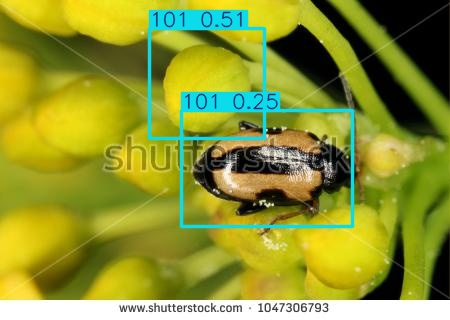

In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display

# Load your trained model
model = YOLO("/content/runs/detect/train/weights/best.pt")  # path to your best.pt

# Specify the image path (change to the image you want to test)
img_path = "/content/IP102/IP102/JPEGImages/IP038000648.jpg"

# Run inference
results = model.predict(source=img_path, save=True, imgsz=640, conf=0.25)  # conf=0.25 is confidence threshold

# Display the result image with bounding boxes
# YOLOv8 automatically saves results in 'runs/detect/predict'
display(Image(filename="/content/runs/detect/predict/" + img_path.split('/')[-1]))

In [ ]:
from ultralytics import YOLO
import os

# Load your trained YOLOv8 model
model = YOLO("/content/runs/detect/train/weights/best.pt")

# Validation images folder
val_images_dir = "/content/IP102/val/images"

# Output folder for detected images
output_dir = "/content/runs/detect/val_results"
os.makedirs(output_dir, exist_ok=True)

# Get all image files
image_files = [f for f in os.listdir(val_images_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]

# Run detection on each image
for img_name in image_files:
    img_path = os.path.join(val_images_dir, img_name)
    results = model.predict(source=img_path, conf=0.05, imgsz=640, save=True, save_dir=output_dir)
    print(f"Processed: {img_name}")

print(f"All results saved to {output_dir}")

Streaming output truncated to the last 5000 lines.
image 1/1 /content/IP102/val/images/IP023000564.jpg: 480x640 2 87s, 2 101s, 4 47s, 8.4ms
Speed: 2.2ms preprocess, 8.4ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict2
Processed: IP023000564.jpg

image 1/1 /content/IP102/val/images/IP102005074.jpg: 512x640 4 87s, 5 101s, 5 50s, 10.6ms
Speed: 2.6ms preprocess, 10.6ms inference, 1.5ms postprocess per image at shape (1, 3, 512, 640)
Results saved to /content/runs/detect/predict2
Processed: IP102005074.jpg

image 1/1 /content/IP102/val/images/IP069000723.jpg: 352x640 3 101s, 3 47s, 3 50s, 14.0ms
Speed: 2.7ms preprocess, 14.0ms inference, 6.4ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /content/runs/detect/predict2
Processed: IP069000723.jpg

image 1/1 /content/IP102/val/images/IP102001903.jpg: 384x640 3 101s, 7 47s, 12.6ms
Speed: 2.4ms preprocess, 12.6ms inference, 1.6ms postprocess per image at shape (1

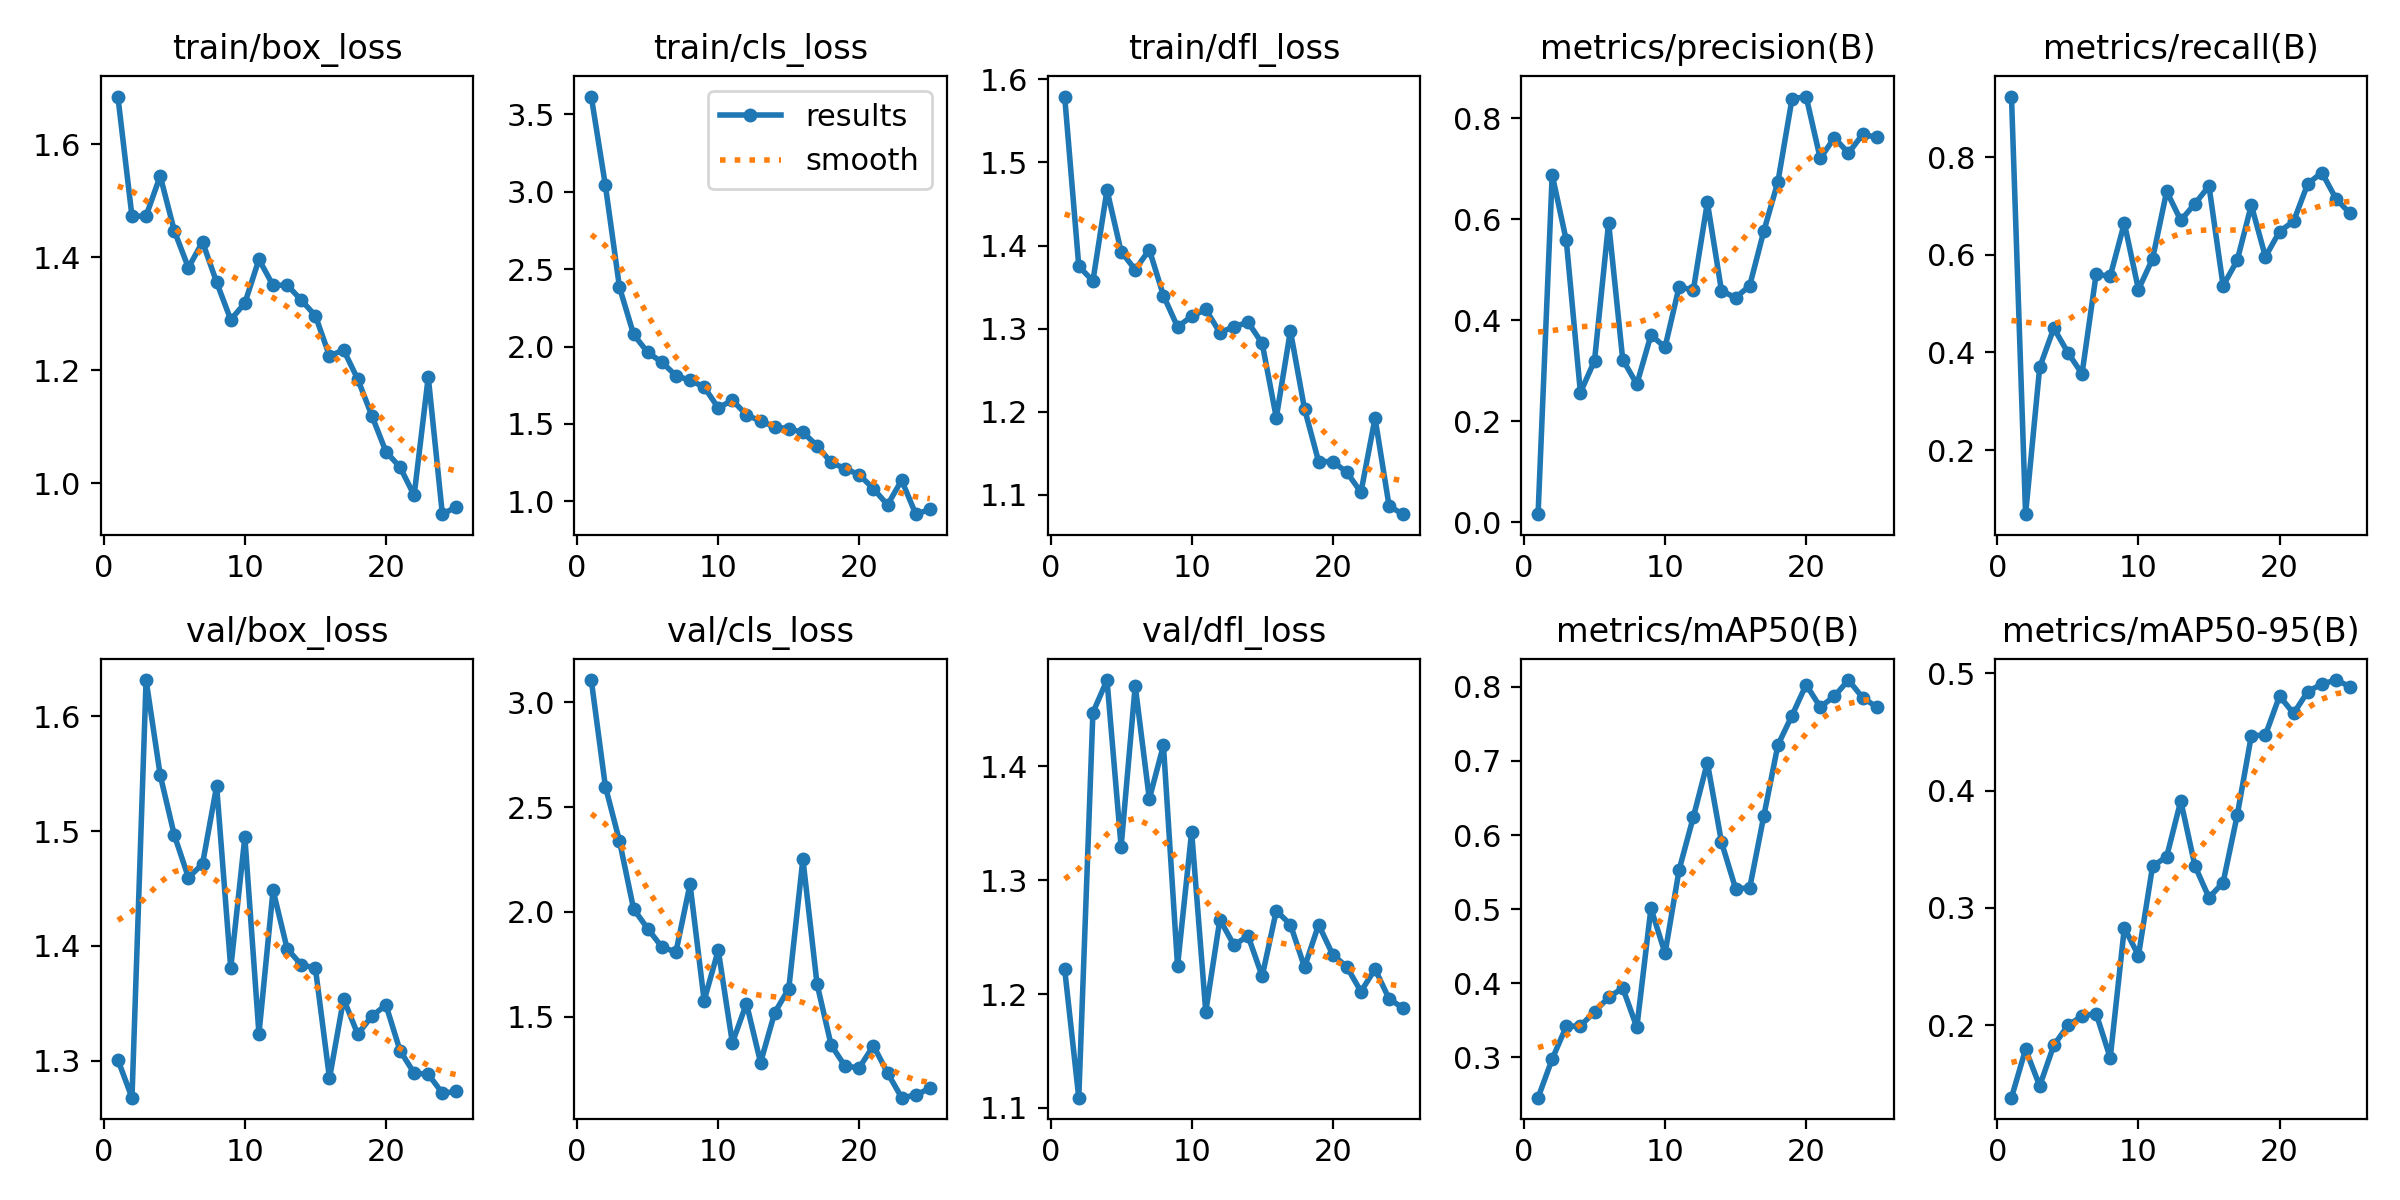

In [ ]:
from IPython.display import Image

# Path where YOLO saves training results
Image(filename="/content/runs/detect/train/results.png", width=800)